Saving DLG_image.jpg to DLG_image (4).jpg


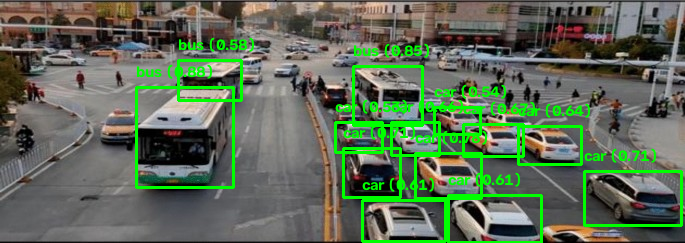

In [7]:

# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------
import tensorflow_hub as hub  # to download the ready-trained model
import tensorflow as tf       # the deep-learning engine
import numpy as np             # for working with number arrays
import cv2                     # OpenCV: open images, draw boxes
from google.colab import files
from google.colab.patches import cv2_imshow  # Colab's replacement for cv2.imshow


# ------------------------------------------------------------
# 2. LOAD THE PRE-TRAINED DETECTOR - "borrow the expert"
# ------------------------------------------------------------

# EfficientDet-D0 is the smallest/fastest version (D0..D7 get bigger & sharper).
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d7/1"
detector = hub.load(MODEL_URL)  # downloads once, then cached


# ------------------------------------------------------------
# 3. CLASS NAMES - the 80 things the model can recognize (COCO dataset)
# ------------------------------------------------------------
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant",
    "stop sign", "parking meter", "bench", "bird", "cat", "dog",
    "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe",
    "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl",
    "banana", "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch", "potted plant",
    "bed", "dining table", "toilet", "tv", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster",
    "sink", "refrigerator", "book", "clock", "vase", "scissors",
    "teddy bear", "hair drier", "toothbrush"
]


# ------------------------------------------------------------
# 4. DETECT OBJECTS AND DRAW BOXES
# ------------------------------------------------------------
def detect_objects_with_boxes(image_path, detector):
    """Run the detector on one image and return the image with boxes drawn."""
    image = cv2.imread(image_path)              # read image (BGR pixels)
    orig_image = image.copy()                   # clean copy to draw on

    input_tensor = tf.convert_to_tensor(image)  # image -> tensor
    input_tensor = input_tensor[tf.newaxis, ...] # add batch axis: here is 1 photo

    detections = detector(input_tensor)          # one forward pass

    num_detections = int(detections["num_detections"])
    detection_boxes = detections["detection_boxes"].numpy()[0]  # WHERE (fractions)
    detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32)  # WHAT
    detection_scores = detections["detection_scores"].numpy()[0]  # HOW SURE

    confidence_threshold = 0.5  # ignore boxes below 50% sure
    for i in range(num_detections):

        score = detection_scores[i]
        if score < confidence_threshold:
            continue

        box = detection_boxes[i]
        h, w, _ = orig_image.shape
        y_min, x_min, y_max, x_max = box  # note: y comes first
        x_min, x_max = int(x_min * w), int(x_max * w)  # fractions -> pixels
        y_min, y_max = int(y_min * h), int(y_max * h)

        class_id = int(detection_classes[i])
        class_name = (
            COCO_CLASSES[class_id - 1]
            if 1 <= class_id <= 80
            else "Unknown"
        )
        label = f"{class_name} ({score:.2f})"

        cv2.rectangle(
            orig_image,
            (x_min, y_min),
            (x_max, y_max),
            (0, 255, 0),
            2
        )
        cv2.putText(
            orig_image,
            label,
            (x_min, y_min - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

    return orig_image


# ------------------------------------------------------------
# 5. RUN IT - pick an image from the browser, detect, show
# ------------------------------------------------------------
uploaded = files.upload()             # "Choose Files" button in the browser
image_path = next(iter(uploaded))     # the file the user picked

result_image = detect_objects_with_boxes(image_path, detector)

cv2_imshow(result_image)              # show in Colab (NOT cv2.imshow)
